In [ ]:
import tensorflow               as tf
import numpy                    as np
import matplotlib.pyplot        as plt
import keras

from tensorflow.keras.models    import load_model
from data_separation            import dataseparation

Saliency_map for K=0


C:\Users\Rubens\AppData\Local\Temp\ipykernel_16484\151622234.py:73: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axes = plt.subplots(1, 3, figsize=(15, 5.5))


Saliency_map for K=1
Saliency_map for K=2
Saliency_map for K=3
Saliency_map for K=4


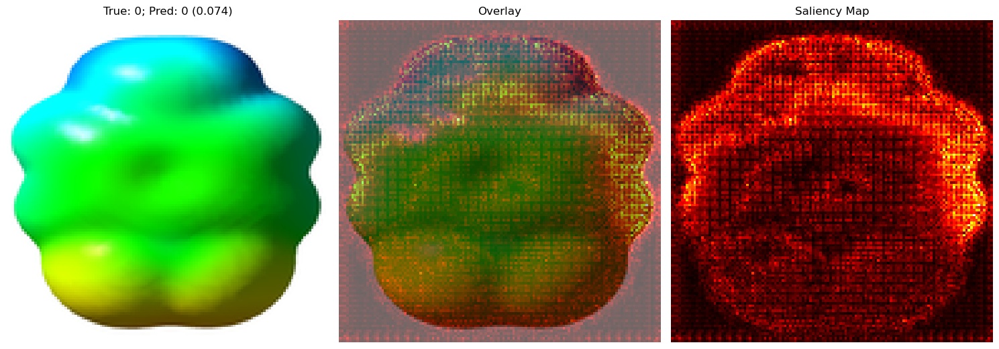

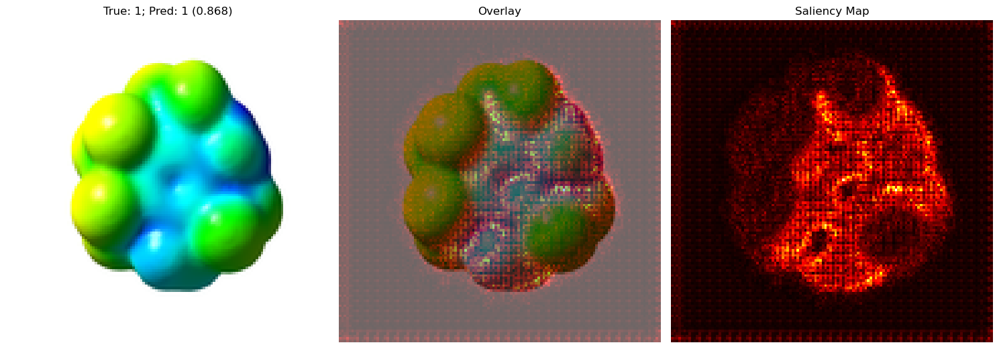

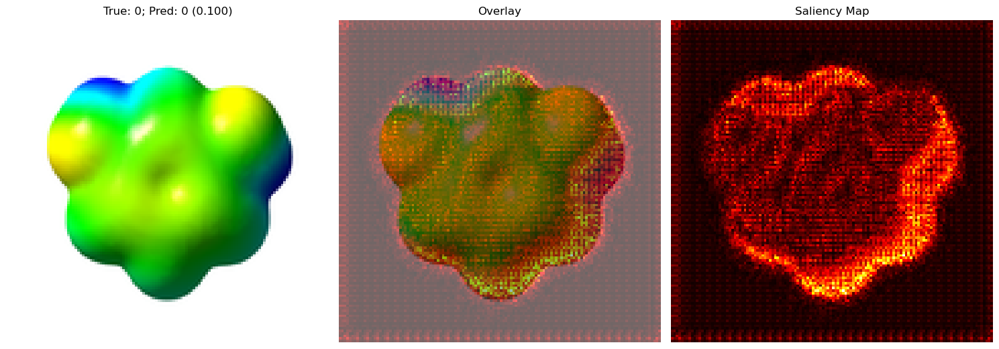

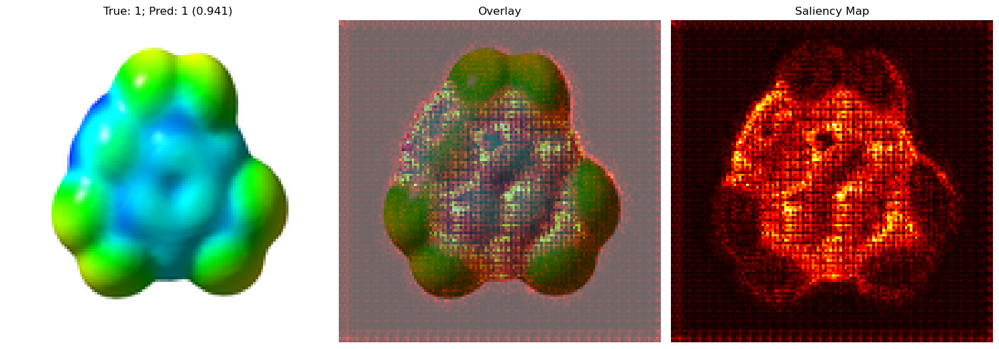

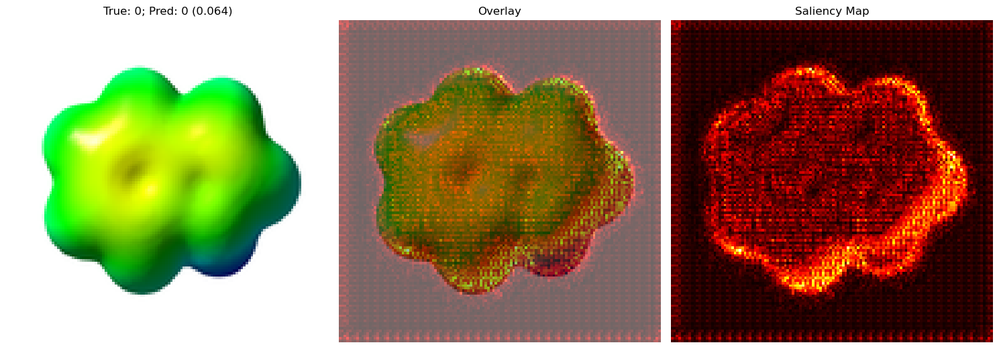

...

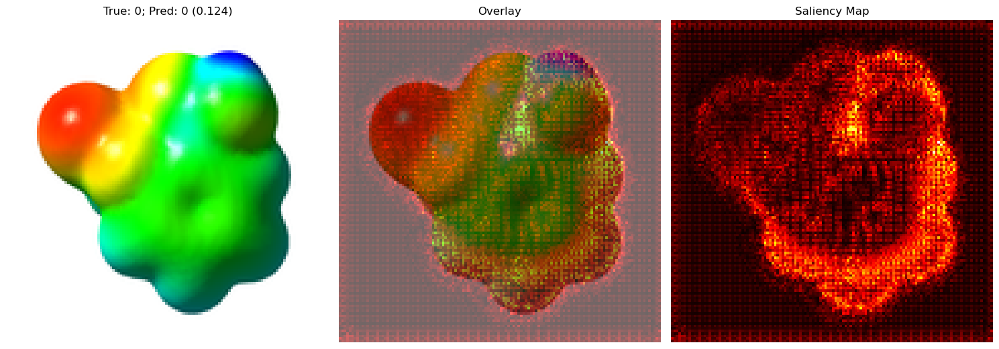

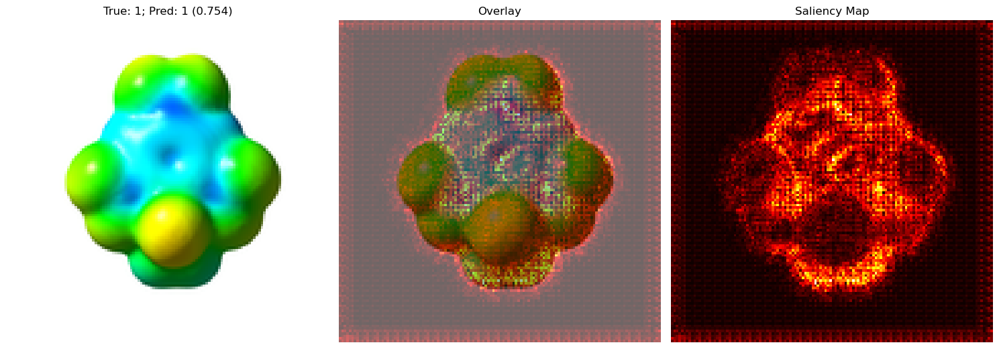

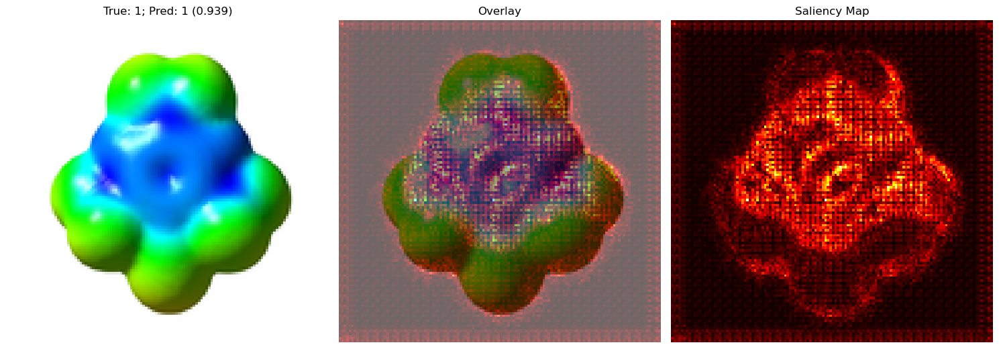

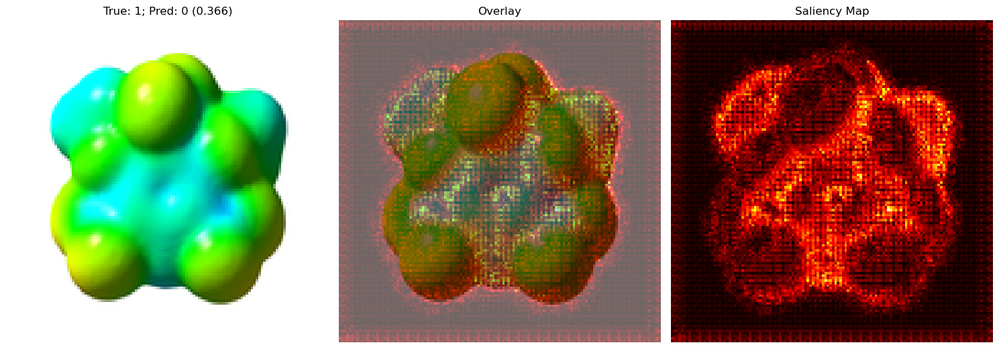

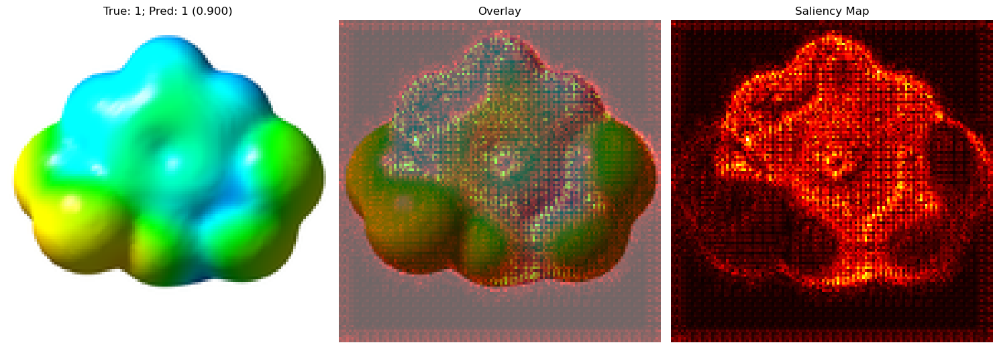

In [13]:
def compute_saliency_map(model, image_array, class_item):
    # 1. Add batch dimension and convert to Tensor
    image_tensor = tf.convert_to_tensor(image_array[None], dtype=tf.float32)

    # 2. Record operations for automatic differentiation
    with tf.GradientTape() as tape:
        tape.watch(image_tensor)
        
        # Forward pass through all layers except the last activation layer (Sigmoid)
        x = image_tensor
        for layer in model.layers[:-1]:
            x = layer(x)
            
        # 3. Manually compute Logits from the final Dense layer (1 neuron)
        last_dense_layer = model.layers[-1]
        logits = tf.matmul(x, last_dense_layer.kernel) + last_dense_layer.bias
        
        loss = logits[:, 0]

        # 4. Define loss based on the target class
        #if class_item == 1:
        #    loss = logits[:, 0]
        #else:
        #    loss = -logits[:, 0]

    # 5. Compute gradients
    grads = tape.gradient(loss, image_tensor)
    
    # 6. Get the maximum absolute value across RGB channels
    saliency = tf.reduce_max(tf.abs(grads), axis=-1)[0]
    
    # 7. Normalize the map between 0 and 1
    saliency_min = tf.reduce_min(saliency)
    saliency_max = tf.reduce_max(saliency)
    
    if tf.abs(saliency_max - saliency_min) < 1e-8:
        return np.zeros_like(saliency.numpy())
    
    saliency = (saliency - saliency_min) / (saliency_max - saliency_min + 1e-8)
    return saliency.numpy()
predByValue = []
# --- Test Loop Execution ---
# Note: Using [:3] to test only the first 3 images to prevent memory issues on large datasets
for j in range(5):
    x_val, x_test, x_train, y_val, y_test, y_train = dataseparation(target_size=(128,128),k=j+1)
    model = load_model(f'./models/ESP-K{j+1}.keras')
    print("=="*60)
    print("=="*60)
    print(f"Saliency_map for K={j}")
    

    for i in range(len(x_test)): 
        pred = model.predict(np.expand_dims(x_test[i], axis=0), verbose=0)[0]
        predReal = pred[0]
        pred = 1 if pred > 0.5 else 0
        #print(pred, y_test[i])
        target_image = x_test[i]
        true_class = y_test[i]

        predByValue.append([true_class, predReal])
        # Generate the original saliency map
        saliency_map = compute_saliency_map(model, target_image, class_item=true_class)

        # --- Size Adjustment (Ensuring equal shapes) ---
        if saliency_map.shape != target_image.shape[:2]:
            # Resize saliency map to match the original image dimensions
            saliency_map = tf.image.resize(saliency_map[..., None], target_image.shape[:2]).numpy().squeeze()

        # Filter out low-level noise
        saliency_masked = np.where(saliency_map < 1e-4, 0.0, saliency_map)

        # --- Plotting with Overlay ---
        fig, axes = plt.subplots(1, 3, figsize=(15, 5.5))

        # 1. Original Image
        axes[0].set_title(f"True: {true_class}; Pred: {pred} ({predReal:.3f})")
        axes[0].imshow(target_image)
        axes[0].axis('off')

        # 3. Overlay (Importance)
        axes[1].set_title("Overlay")
        axes[1].imshow(target_image)
        axes[1].imshow(saliency_masked, cmap='hot', vmin=0, vmax=1, alpha=0.6)
        axes[1].axis('off')

        # 2. Saliency Map (Isolated Heatmap)
        axes[2].set_title("Saliency Map")
        axes[2].imshow(saliency_masked, cmap='hot', vmin=0, vmax=1)
        axes[2].axis('off')

        # Adding the colorbar specifically to the third axis prevents it from distorting the second plot
        #fig.colorbar(overlay, ax=axes[2], fraction=0.046, pad=0.04)

        plt.tight_layout()
        plt.savefig(f"./heat_maps/k{j+1}/heat_map_{i+1}")




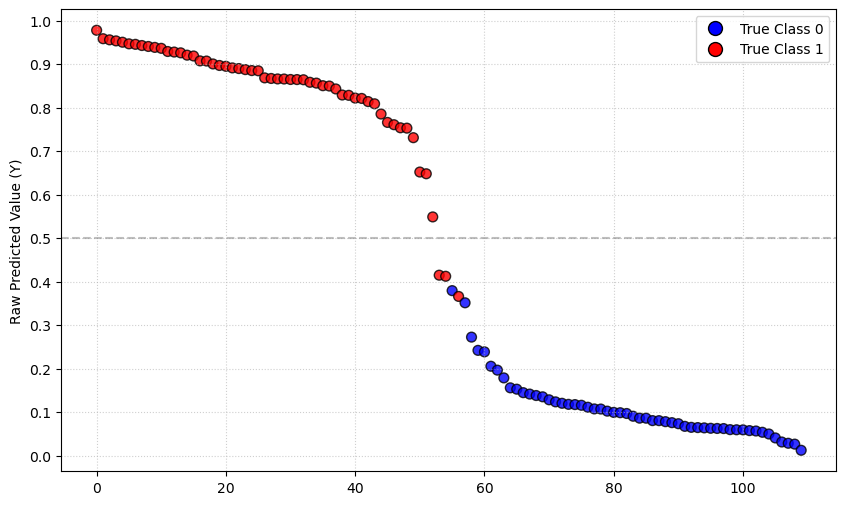

In [16]:
# --- 1. DESCENDING ORDER SORTING ---
# Sorts based on the second element of each sublist (index 1 -> raw_pred)
# reverse=True ensures the descending order
predByValue.sort(key=lambda x: x[1], reverse=True)

# --- 2. DATA PREPARATION FOR THE PLOT ---
indices = np.arange(len(predByValue))          # X-axis: indices from 0 to N-1
predicted_values = [item[1] for item in predByValue]  # Y-axis
true_classes = [item[0] for item in predByValue]      # For color mapping

# Color mapping: Blue for Class 0, Red for Class 1
colors = ['blue' if c == 0 else 'red' for c in true_classes]

# --- 3. PLOTTING ---
plt.figure(figsize=(10, 6))

# Creating the scatter plot
scatter = plt.scatter(indices, predicted_values, c=colors, edgecolors='black', alpha=0.8, s=50)

# Adding a decision threshold line at 0.5 for visual reference (optional)
plt.axhline(y=0.5, color='gray', linestyle='--', alpha=0.5, label='Decision Threshold (0.5)')
plt.yticks(np.arange(0.0, 1.1, 0.1))

# Plot customization
# plt.xlabel('Vector Index (Sorted)')
plt.ylabel('Raw Predicted Value (Y)')
plt.grid(True, linestyle=':', alpha=0.6)

# Manual legend creation
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], marker='o', color='w', label='True Class 0', markerfacecolor='blue', markersize=10, markeredgecolor='black'),
    Line2D([0], [0], marker='o', color='w', label='True Class 1', markerfacecolor='red', markersize=10, markeredgecolor='black')
]
plt.legend(handles=legend_elements, loc='upper right')

# Display the current plot
plt.show()

In [ ]:
def compute_saliency_map(model, image_array, class_item):
    # 1. Add batch dimension and convert to Tensor
    image_tensor = tf.convert_to_tensor(image_array[None], dtype=tf.float32)

    # 2. Record operations for automatic differentiation
    with tf.GradientTape() as tape:
        tape.watch(image_tensor)
        
        # Forward pass through all layers except the last activation layer (Sigmoid)
        x = image_tensor
        for layer in model.layers[:-1]:
            x = layer(x)
            
        # 3. Manually compute Logits from the final Dense layer (1 neuron)
        last_dense_layer = model.layers[-1]
        logits = tf.matmul(x, last_dense_layer.kernel) + last_dense_layer.bias

        #print(logits[:, 0])
        #print(-logits[:, 0])
        
        # 4. Define loss based on the target class
        if class_item == 1:
            loss = -logits[:, 0]
        else:
            loss = logits[:, 0]



    # 5. Compute gradients
    grads = tape.gradient(loss, image_tensor)[0] # Removido o [0] do reduce_max para cá

    # Em vez de aplicar abs direto em tudo, separamos:
    # Pixels que empurram a predição para CIMA
    positive_grads = tf.clip_by_value(grads, clip_value_min=0, clip_value_max=tf.reduce_max(grads))
    # Pixels que empurram a predição para BAIXO
    negative_grads = tf.clip_by_value(grads, clip_value_min=tf.reduce_min(grads), clip_value_max=0)
    negative_grads = tf.abs(negative_grads) # Tornamos positivo apenas para conseguir plotar

    # Agora você escolhe qual quer retornar (ou retorna ambos)
    # Exemplo para os gradientes positivos:
    saliency = tf.reduce_max(positive_grads, axis=-1)

    
    
    # 7. Normalize the map between 0 and 1
    saliency_min = tf.reduce_min(saliency)
    saliency_max = tf.reduce_max(saliency)
    
    if tf.abs(saliency_max - saliency_min) < 1e-8:
        return np.zeros_like(saliency.numpy())
    
    saliency = (saliency - saliency_min) / (saliency_max - saliency_min + 1e-8)
    return saliency.numpy()

# --- Test Loop Execution ---
# Note: Using [:3] to test only the first 3 images to prevent memory issues on large datasets
for j in range(1):
    x_val, x_test, x_train, y_val, y_test, y_train = dataseparation(target_size=(128,128),k=j+1)
    model = load_model(f'./models/ESP-K{j+1}.keras')
    print("=="*60)
    print("=="*60)
    print(f"Saliency_map for K={j}")
    for i in range(len(x_test)): 
        pred = model.predict(np.expand_dims(x_test[i], axis=0), verbose=0)[0]
        pred = 1 if pred > 0.5 else 0
        print(pred, y_test[i])
        target_image = x_test[i]
        true_class = y_test[i]

        # Generate the original saliency map
        saliency_map = compute_saliency_map(model, target_image, class_item=true_class)

        # --- Size Adjustment (Ensuring equal shapes) ---
        if saliency_map.shape != target_image.shape[:2]:
            # Resize saliency map to match the original image dimensions
            saliency_map = tf.image.resize(saliency_map[..., None], target_image.shape[:2]).numpy().squeeze()

        # Filter out low-level noise
        saliency_masked = np.where(saliency_map < 1e-4, 0.0, saliency_map)

        # --- Plotting with Overlay ---
        fig, axes = plt.subplots(1, 3, figsize=(15, 6))

        # 1. Original Image
        axes[0].set_title(f"True: {true_class}; Pred: {pred}")
        axes[0].imshow(target_image)
        axes[0].axis('off')

        # 3. Overlay (Importance)
        axes[1].set_title("Overlay (Importance)")
        axes[1].imshow(target_image)
        axes[1].imshow(saliency_masked, cmap='hot', vmin=0, vmax=1, alpha=0.6)
        axes[1].axis('off')

        # 2. Saliency Map (Isolated Heatmap)
        axes[2].set_title("Saliency Map")
        axes[2].imshow(saliency_masked, cmap='hot', vmin=0, vmax=1)
        axes[2].axis('off')

        # Adding the colorbar specifically to the third axis prevents it from distorting the second plot
        #fig.colorbar(overlay, ax=axes[2], fraction=0.046, pad=0.04)

        plt.tight_layout()
        plt.savefig(f"./heat_maps/k{j+1}-negative/heat_map_{i+1}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step
[[13  0]
 [ 1  8]]


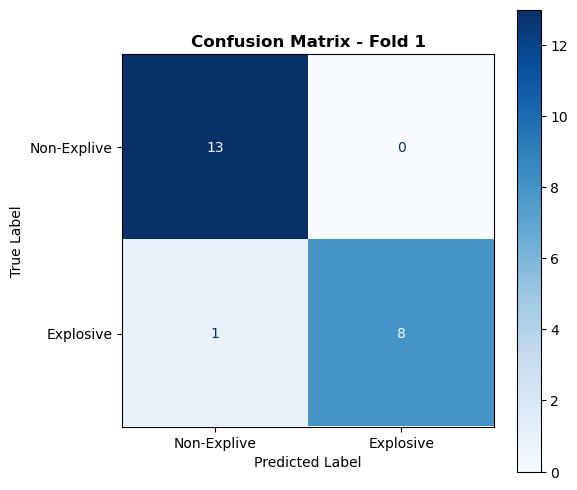

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step
[[10  0]
 [ 1 11]]


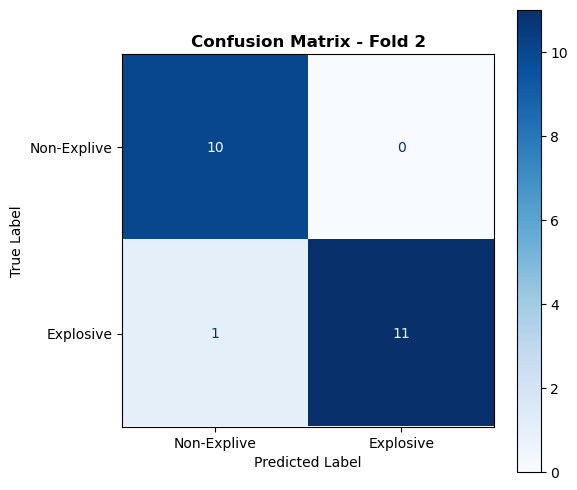

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step
[[11  0]
 [ 0 11]]


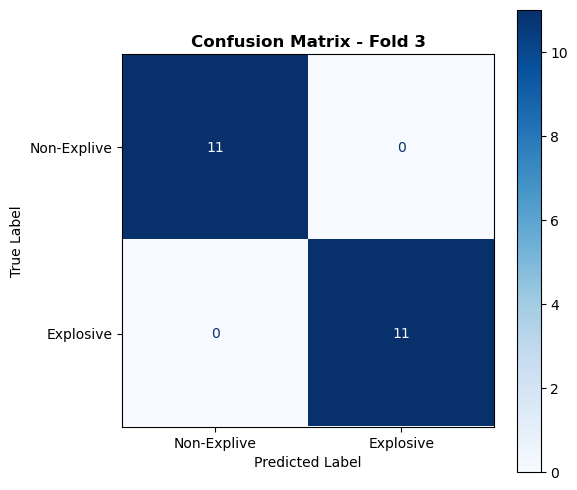

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step
[[10  0]
 [ 0 12]]


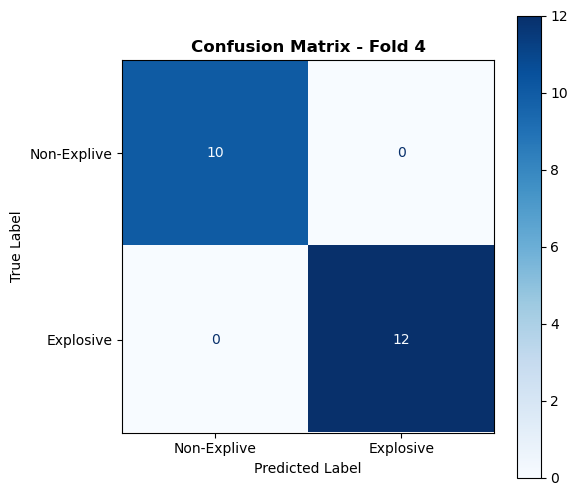

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step
[[10  0]
 [ 1 11]]


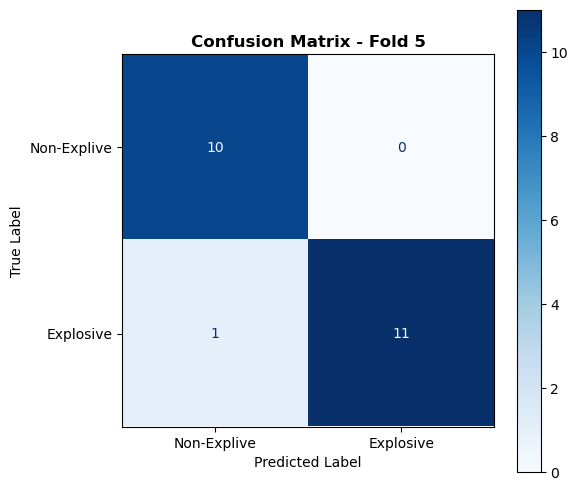

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step
[[11  0]
 [ 2  6]]


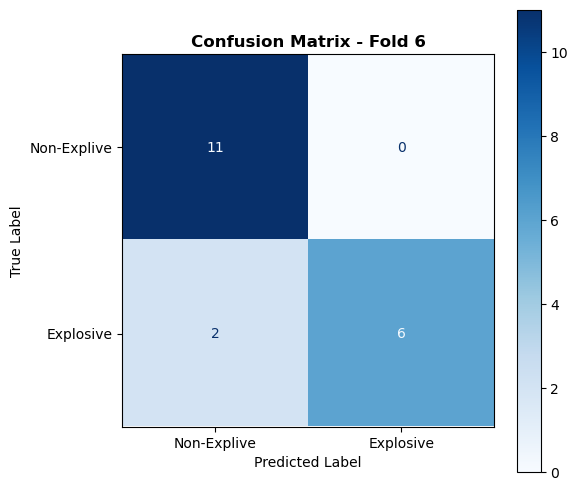

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

for i in range(5):

    x_val, x_test, x_train, y_val, y_test, y_train = dataseparation(target_size=(128,128),k=i+1)

    # 1. Generate continuous raw probabilities from the model
    model = load_model(f'./models/ESP-K{i+1}.keras')
    pred = model.predict(x_test)

    # 2. Convert probabilities to binary class labels (0 or 1)
    # Values > 0.5 become 1, values <= 0.5 become 0
    y_pred_classes = (pred > 0.5).astype(int)

    # 3. Ensure true test labels are flat 1D integers to match predictions
    y_true_classes = np.array(y_test).astype(int)

    # 4. Compute the raw confusion matrix numerical data
    cm = confusion_matrix(y_true_classes, y_pred_classes)
    print(cm)

    # 5. Set up the visual display configuration
    # Replace display_labels strings with your actual class names if needed
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Non-Explive', 'Explosive'])

    # 6. Plot and style the matrix
    fig, ax = plt.subplots(figsize=(6, 6))
    disp.plot(cmap='Blues', ax=ax, values_format='d')  # 'd' displays integers clearly

    ax.set_title(f'Confusion Matrix - Fold {i+1}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Predicted Label', fontsize=10)
    ax.set_ylabel('True Label', fontsize=10)

    # 7. Save and display the visualization
    plt.savefig(f"./metrics/Confusion_Matrix_{i+1}.png", bbox_inches='tight')
    plt.show()

In [7]:
import time
from datetime import datetime
inicio = datetime.now()

print(f"The process start at: {inicio}")

fim = datetime.now()

print(fim-inicio)


The process start at: 2026-05-27 12:01:25.630145
0:00:00
